# 02456 Deep Learning Project: PINNs: Physics-informed neural networks

The notebook contains Task 2 from the project pdf

In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
import torch.optim as optim
import torch.nn.init as init
from torch.nn.parameter import Parameter

# use a double precision for the gradient check.   
torch.set_default_dtype(torch.float64)
print("numpy", np.__version__, "| matplotlib", matplotlib.__version__, "| torch", torch.__version__)

numpy 2.0.2 | matplotlib 3.9.4 | torch 2.8.0


In [3]:
import numpy as np

# parameters

m, mu, k = 1.0, 5.0, 500.0 

# damping and frequencies

d   = mu / (2 * m) 
w0  = np.sqrt(k)
w   = np.sqrt(w0**2 - d**2)

# phase and amplitude

phi = np.arctan(-d / w)
A   = 1 / (2 * np.cos(phi))

def exact(t):
    return np.exp(-d * t) * (2 * A * np.cos(phi + w * t))

# data points generating

t_data = np.linspace(0, 0.5, 10)
x_data = exact(t_data)
print("t_data:", t_data)
print("x_data:", x_data)


t_data: [0.         0.05555556 0.11111111 0.16666667 0.22222222 0.27777778
 0.33333333 0.38888889 0.44444444 0.5       ]
x_data: [ 1.00000000e+00  3.79657815e-01 -5.39370953e-01 -5.97418836e-01
  6.53678406e-02  4.90074447e-01  2.32009076e-01 -2.37936847e-01
 -3.12421446e-01  7.58575452e-04]


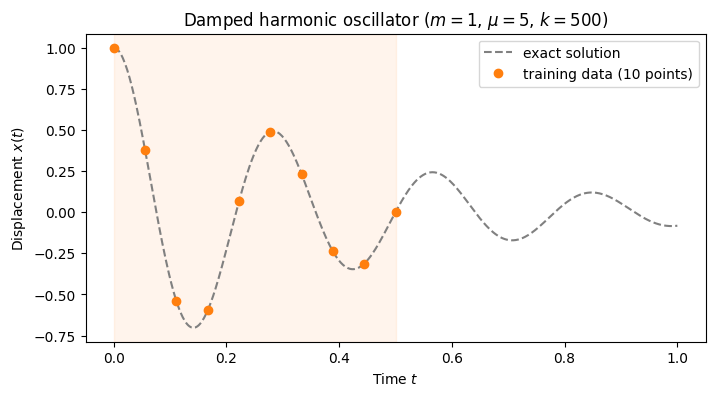

In [4]:
t_test = np.linspace(0, 1, 500)  # time range for plotting

plt.figure(figsize=(8, 4))
plt.plot(t_test, exact(t_test), color='grey', ls='--', label='exact solution')
plt.plot(t_data, x_data, 'o', color='tab:orange', label='training data (10 points)') # analytical solution and the training points
plt.axvspan(0, 0.5, color='tab:orange', alpha=0.08) # time interval used for training data
plt.xlabel('Time $t$') 
plt.ylabel('Displacement $x(t)$')
plt.title(r'Damped harmonic oscillator ($m=1$, $\mu=5$, $k=500$)')
plt.legend()
plt.show()

In [5]:
# numpy arrays to PyTorch tensors and into column vectors

t_train = torch.from_numpy(t_data).view(-1, 1)
x_train = torch.from_numpy(x_data).view(-1, 1)
t_eval = torch.from_numpy(t_test).view(-1, 1)

print("t_train", t_train.shape, "| x_train", x_train.shape, "| t_eval", t_eval.shape)

t_train torch.Size([10, 1]) | x_train torch.Size([10, 1]) | t_eval torch.Size([500, 1])


In [6]:
class Net(nn.Module):

    def __init__(self, num_hidden, w1_std=10.0):
        super(Net, self).__init__()

        # weights and biases for the hidden layer

        self.W_1 = Parameter(init.normal_(torch.empty(num_hidden, 1), 0, w1_std))
        self.b_1 = Parameter(-self.W_1.detach().view(-1) * torch.rand(num_hidden))

        #  output layer initialization

        self.W_2 = Parameter(init.xavier_normal_(torch.empty(1, num_hidden)))
        self.b_2 = Parameter(init.constant_(torch.empty(1), 0))

    def forward(self, t):
        h = torch.tanh(F.linear(t, self.W_1, self.b_1))
        return F.linear(h, self.W_2, self.b_2)

In [7]:
def train_data_only(net, num_epochs=20000, lr=1e-3, print_every=2000):
    optimizer = optim.Adam(net.parameters(), lr=lr) # optimizer and loss function
    criterion = nn.MSELoss()
    losses = []

# Train the network

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        loss = criterion(net(t_train), x_train)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        if print_every and epoch % print_every == 0:
            print(f"Epoch {epoch:5d} : Train MSE {losses[-1]:.3e}")
    return losses

# initialize and train the network

num_hidden = 32
torch.manual_seed(0)
net = Net(num_hidden)
losses = train_data_only(net)
print(f"Final train MSE {losses[-1]:.3e}")

Epoch     0 : Train MSE 4.863e-01
Epoch  2000 : Train MSE 9.252e-04
Epoch  4000 : Train MSE 4.103e-04
Epoch  6000 : Train MSE 5.093e-05
Epoch  8000 : Train MSE 7.276e-08
Epoch 10000 : Train MSE 1.904e-12
Epoch 12000 : Train MSE 2.871e-14
Epoch 14000 : Train MSE 4.686e-07
Epoch 16000 : Train MSE 7.720e-12
Epoch 18000 : Train MSE 2.174e-13
Final train MSE 3.005e-14


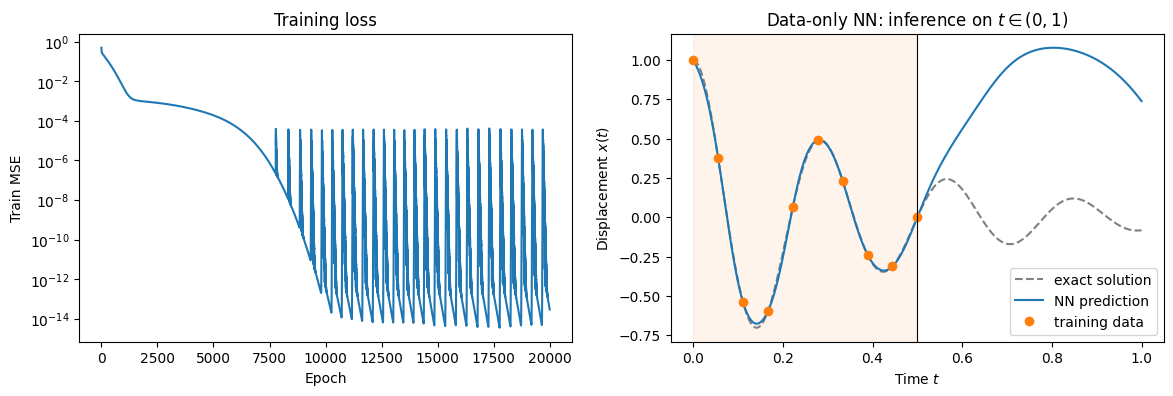

MSE vs exact solution on [0, 0.5]: 1.96e-04
MSE vs exact solution on (0.5, 1]: 7.50e-01


In [8]:
# network on the full time range

with torch.no_grad():
    x_pred = net(t_eval).numpy().ravel()
x_exact = exact(t_test)

#  training loss and the network prediction

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.semilogy(losses)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Train MSE')
ax1.set_title('Training loss')

ax2.plot(t_test, x_exact, color='grey', ls='--', label='exact solution')
ax2.plot(t_test, x_pred, color='tab:blue', label='NN prediction')
ax2.plot(t_data, x_data, 'o', color='tab:orange', label='training data')
ax2.axvspan(0, 0.5, color='tab:orange', alpha=0.08)
ax2.axvline(0.5, color='k', lw=0.8)
ax2.set_xlabel('Time $t$')
ax2.set_ylabel('Displacement $x(t)$')
ax2.set_title('Data-only NN: inference on $t \\in (0, 1)$')
ax2.legend()
plt.show()

# prediction errors inside and outside the training interval

inside, outside = t_test <= 0.5, t_test > 0.5
print(f"MSE vs exact solution on [0, 0.5]: {np.mean((x_pred[inside] - x_exact[inside])**2):.2e}")
print(f"MSE vs exact solution on (0.5, 1]: {np.mean((x_pred[outside] - x_exact[outside])**2):.2e}")

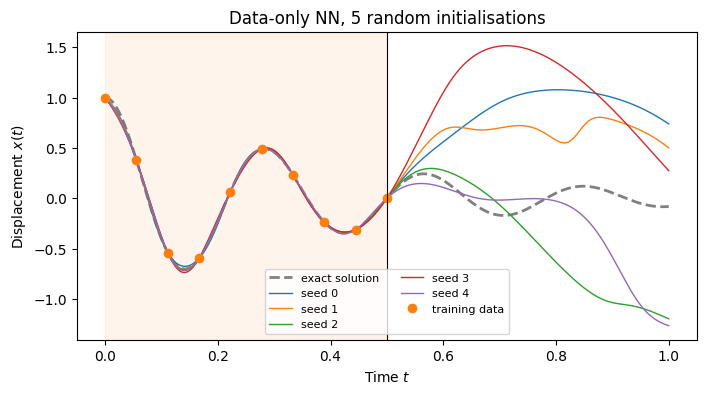

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(t_test, x_exact, color='grey', ls='--', lw=2, label='exact solution') # exact solution as a reference

# train the network with 5 diff initialisations

for seed in range(5):
    torch.manual_seed(seed)
    net_seed = Net(num_hidden)
    train_data_only(net_seed, print_every=0)
    with torch.no_grad():
        plt.plot(t_test, net_seed(t_eval).numpy().ravel(), lw=1, label=f'seed {seed}')
plt.plot(t_data, x_data, 'o', color='tab:orange', label='training data')
plt.axvspan(0, 0.5, color='tab:orange', alpha=0.08)
plt.axvline(0.5, color='k', lw=0.8)
plt.xlabel('Time $t$')
plt.ylabel('Displacement $x(t)$')
plt.title('Data-only NN, 5 random initialisations')
plt.legend(ncol=2, fontsize=8)
plt.show()

In [10]:
# make collocation points at the centres of equal intervals in [0, 1]

N_phys = 100
t_phys = ((torch.arange(N_phys) + 0.5) / N_phys).view(-1, 1)   # centres of N_phys equal sub-intervals of [0, 1]
t_0 = torch.zeros(1, 1) #  time for the initial condition

# loss weights and training parameters

lambda_phys = 1e-5
lambda_ic = 1e-1
num_epochs = 20000
lr = 1e-3

dist = (t_train - t_phys.T).abs() #  distances between training data and collocation points check
print(f"{N_phys} collocation points on [{t_phys.min():.3f}, {t_phys.max():.3f}], spacing {1 / N_phys}")
print(f"data points coinciding with a collocation point: {(dist < 1e-12).sum().item()} "
      f"(smallest distance between a data point and a collocation point: {dist.min():.4f})")

100 collocation points on [0.005, 0.995], spacing 0.01
data points coinciding with a collocation point: 0 (smallest distance between a data point and a collocation point: 0.0006)


In [11]:
def network_derivatives(t, W_1, b_1, W_2, b_2):

    # hidden layer activations

    h = torch.tanh(F.linear(t, W_1, b_1))        
    s = 1 - h**2                       

    # network output and derivatives with respect to time

    x = F.linear(h, W_2, b_2)                       
    dx = F.linear(s * W_1.T, W_2)                  
    d2x = F.linear(-2 * W_1.T**2 * h * s, W_2)     
    return h, s, x, dx, d2x


def param_grads(t, a, b, c, W_1, b_1, W_2, b_2):
    # a, b, c - the loss derivatives with respect to x, dx/dt and d2x/dt2
    h, s, _, _, _ = network_derivatives(t, W_1, b_1, W_2, b_2)
    w1, w2 = W_1.T, W_2
    q = 1 - 3 * h**2

    # gradients for each network parameter

    dW_1 = (w2 * s * (a * t + b * (1 - 2 * t * w1 * h) - 2 * c * w1 * (2 * h + t * w1 * q))).sum(0).view(-1, 1)
    db_1 = (w2 * s * (a - 2 * b * w1 * h - 2 * c * w1**2 * q)).sum(0)
    dW_2 = (a * h + b * s * w1 - 2 * c * w1**2 * h * s).sum(0, keepdim=True)
    db_2 = a.sum(0)
    return [dW_1, db_1, dW_2, db_2]


def loss_and_grads(W_1, b_1, W_2, b_2, lambda_phys, lambda_ic):
    params = (W_1, b_1, W_2, b_2)

    # data loss based on the available training points

    _, _, x_d, _, _ = network_derivatives(t_train, *params)
    e = x_d - x_train
    L_data = torch.mean(e**2)

    # physics loss

    _, _, x_c, dx_c, d2x_c = network_derivatives(t_phys, *params)
    r = d2x_c + mu / m * dx_c + k / m * x_c
    L_phys = torch.mean(r**2)

    _, _, x_0, dx_0, _ = network_derivatives(t_0, *params)
    L_ic = torch.sum((x_0 - 1)**2 + dx_0**2)

    # combine the three loss terms

    L = L_data + lambda_phys * L_phys + lambda_ic * L_ic

    zeros_d, zeros_0 = torch.zeros_like(e), torch.zeros_like(x_0)
    dL_dr = 2 * lambda_phys * r / len(t_phys)

    # parameter gradients for each loss component

    g_data = param_grads(t_train, 2 * e / len(t_train), zeros_d, zeros_d, *params)
    g_phys = param_grads(t_phys, k / m * dL_dr, mu / m * dL_dr, dL_dr, *params)
    g_ic = param_grads(t_0, 2 * lambda_ic * (x_0 - 1), 2 * lambda_ic * dx_0, zeros_0, *params)

    # gradient contributions together

    grads = [gd + gp + gi for gd, gp, gi in zip(g_data, g_phys, g_ic)]

    return L, (L_data, L_phys, L_ic), grads

In [ ]:
# initialization of a network and its parameters for testing

torch.manual_seed(0)
net_check = Net(num_hidden)
params = [p.detach() for p in net_check.parameters()]

# comparing analytical derivatives with finite - difference approximations

_, _, x, dx, d2x = network_derivatives(t_eval, *params)
eps = 1e-4
with torch.no_grad():
    x_plus, x_minus = net_check(t_eval + eps), net_check(t_eval - eps)
    print("forward pass matches net(t):", torch.allclose(x, net_check(t_eval)))
dx_fd = (x_plus - x_minus) / (2 * eps)
d2x_fd = (x_plus - 2 * x + x_minus) / eps**2
print(f"dx/dt    : max |analytic - FD| = {(dx - dx_fd).abs().max():.1e}   (max |dx/dt|    = {dx.abs().max():.1e})")
print(f"d2x/dt2  : max |analytic - FD| = {(d2x - d2x_fd).abs().max():.1e}   (max |d2x/dt2|  = {d2x.abs().max():.1e})")

# loss components and manually calculated gradient check

L, (L_data, L_phys, L_ic), grads = loss_and_grads(*params, lambda_phys, lambda_ic)
print(f"\nAt initialisation: L_data = {L_data:.3e}, L_phys = {L_phys:.3e}, L_IC = {L_ic:.3e}")
print(f"L = L_data + {lambda_phys:g} * L_phys + {lambda_ic:g} * L_IC = {L:.3e}")
for name, p, g in zip(["W_1", "b_1", "W_2", "b_2"], params, grads):
    print(f"dL/d{name}: shape {tuple(g.shape)} (parameter {tuple(p.shape)}), norm {g.norm():.3e}")

forward pass matches net(t): True
dx/dt    : max |analytic - FD| = 1.4e-05   (max |dx/dt|    = 1.0e+01)
d2x/dt2  : max |analytic - FD| = 3.0e-04   (max |d2x/dt2|  = 2.0e+02)

At initialisation: L_data = 4.863e-01, L_phys = 3.990e+04, L_IC = 9.565e-01
L = L_data + 1e-05 * L_phys + 0.1 * L_IC = 9.809e-01
dL/dW_1: shape (32, 1) (parameter (32, 1)), norm 4.161e-01
dL/db_1: shape (32,) (parameter (32,)), norm 9.366e-01
dL/dW_2: shape (1, 32) (parameter (1, 32)), norm 8.076e+00
dL/db_2: shape (1,) (parameter (1,)), norm 1.943e+00


In [13]:
def loss_value(params):
    L, _, _ = loss_and_grads(*params, lambda_phys, lambda_ic) # total loss for the given parameter values
    return L


def finite_difference_grad(params, idx, eps=1e-5):
    grad_fd = torch.zeros_like(params[idx])
    for j in range(params[idx].numel()):

        # copies to do one parameter at a time

        params_plus = [p.clone() for p in params]
        params_minus = [p.clone() for p in params]
        params_plus[idx].view(-1)[j] += eps
        params_minus[idx].view(-1)[j] -= eps
        grad_fd.view(-1)[j] = (loss_value(params_plus) - loss_value(params_minus)) / (2 * eps)
    return grad_fd

In [14]:
# network gradient check setup

torch.manual_seed(1)
net_fd = Net(num_hidden)
params = [p.detach().clone() for p in net_fd.parameters()]
param_names = ["W_1", "b_1", "W_2", "b_2"]

# calculate the gradients

_, _, grads_analytic = loss_and_grads(*params, lambda_phys, lambda_ic)
grads_fd = [finite_difference_grad(params, idx, eps=1e-5) for idx in range(4)]

# analytical and numerical gradients

print(f"{'parameter':10s} {'entries':>7s} {'||analytic||':>13s} {'max |analytic - FD|':>20s} {'||analytic - FD|| / ||analytic||':>32s}")
for name, g_an, g_fd in zip(param_names, grads_analytic, grads_fd):
    rel = (g_an - g_fd).norm() / g_an.norm()
    print(f"{name:10s} {g_an.numel():7d} {g_an.norm():13.4e} {(g_an - g_fd).abs().max():20.2e} {rel:32.2e}")

# display first few entries

print("\nFirst 8 entries of dL/dW_1:")
print(f"{'i':>3s} {'analytic':>15s} {'finite diff.':>15s} {'|difference|':>13s}")
for i in range(8):
    a, f = grads_analytic[0][i, 0].item(), grads_fd[0][i, 0].item()
    print(f"{i:3d} {a:15.8f} {f:15.8f} {abs(a - f):13.2e}")

parameter  entries  ||analytic||  max |analytic - FD| ||analytic - FD|| / ||analytic||
W_1             32    7.0307e-01             5.16e-11                         1.79e-10
b_1             32    2.3938e+00             7.11e-11                         6.39e-11
W_2             32    2.1489e+01             8.01e-11                         9.22e-12
b_2              1    5.7130e+00             1.86e-11                         3.25e-12

First 8 entries of dL/dW_1:
  i        analytic    finite diff.  |difference|
  0     -0.01071990     -0.01071990      5.83e-12
  1     -0.01951682     -0.01951682      2.40e-11
  2     -0.03536841     -0.03536841      2.79e-11
  3      0.15076314      0.15076314      8.65e-12
  4      0.09616873      0.09616873      5.54e-12
  5     -0.02989267     -0.02989267      7.06e-12
  6      0.03663396      0.03663396      1.13e-11
  7     -0.06788173     -0.06788173      1.41e-11


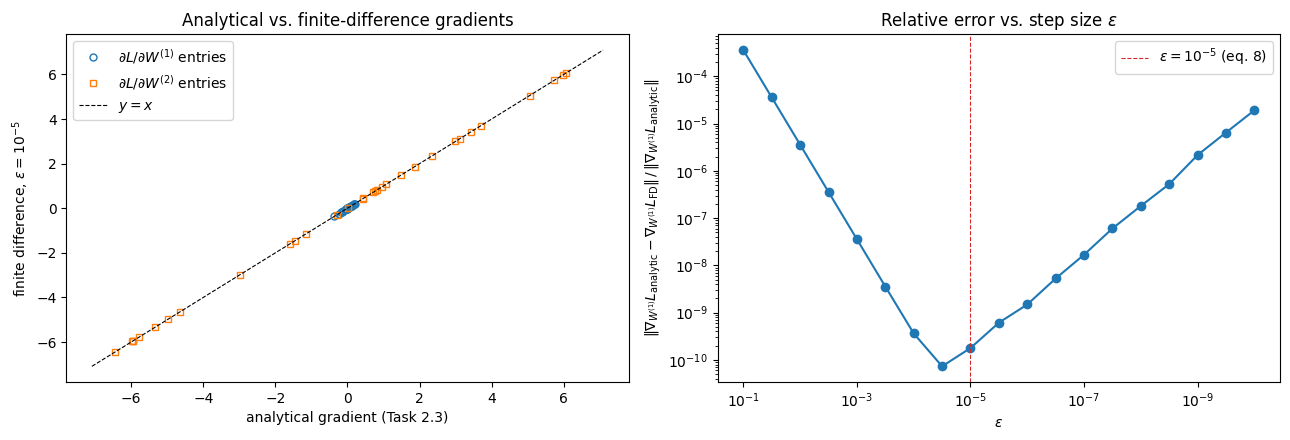

smallest relative error 7.3e-11 at eps = 3.2e-05


In [15]:
# accuracy check


eps_values = np.logspace(-1, -10, 19)
rel_errors = []
for eps in eps_values:
    g_fd = finite_difference_grad(params, 0, eps=eps)
    rel_errors.append(((grads_analytic[0] - g_fd).norm() / grads_analytic[0].norm()).item())

# gradient comparison and relative error check

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for name, g_an, g_fd, marker in zip(param_names[::2], grads_analytic[::2], grads_fd[::2], ["o", "s"]):
    ax1.plot(g_an.view(-1), g_fd.view(-1), marker, ms=5, mfc='none', label=f'$\\partial L / \\partial {name[0]}^{{({name[-1]})}}$ entries')
lim = max(g.abs().max().item() for g in grads_analytic[::2]) * 1.1
ax1.plot([-lim, lim], [-lim, lim], 'k--', lw=0.8, label='$y = x$')
ax1.set_xlabel('analytical gradient (Task 2.3)')
ax1.set_ylabel(f'finite difference, $\\epsilon = 10^{{-5}}$')
ax1.set_title('Analytical vs. finite-difference gradients')
ax1.legend()

ax2.loglog(eps_values, rel_errors, 'o-')
ax2.axvline(1e-5, color='tab:red', ls='--', lw=0.8, label='$\\epsilon = 10^{-5}$ (eq. 8)')
ax2.invert_xaxis()
ax2.set_xlabel('$\\epsilon$')
ax2.set_ylabel('$\\|\\nabla_{W^{(1)}}L_{\\mathrm{analytic}} - \\nabla_{W^{(1)}}L_{\\mathrm{FD}}\\| \\, / \\, \\|\\nabla_{W^{(1)}}L_{\\mathrm{analytic}}\\|$')
ax2.set_title('Relative error vs. step size $\\epsilon$')
ax2.legend()
plt.tight_layout()
plt.show()

# step size that gives the smallest relative error
best = int(np.argmin(rel_errors))
print(f"smallest relative error {rel_errors[best]:.1e} at eps = {eps_values[best]:.1e}")

In [16]:
def train_pinn_manual(lambda_phys, lambda_ic, num_epochs=num_epochs, lr=lr, seed=0, print_every=0,
                      loss_fn=loss_and_grads, net=None):

    # initialise a new network if one is not provided

    if net is None:
        torch.manual_seed(seed)
        net = Net(num_hidden)
    optimizer = optim.Adam(net.parameters(), lr=lr)
    history = {"L": [], "L_data": [], "L_phys": [], "L_ic": []}

# network using manually calculated gradients

    with torch.no_grad():
        for epoch in range(num_epochs):
            params = [p.detach() for p in net.parameters()]
            L, (L_data, L_phys, L_ic), grads = loss_fn(*params, lambda_phys, lambda_ic)

            # assign calculated gradients and update the parameters

            for p, g in zip(net.parameters(), grads):
                p.grad = g
            optimizer.step()

            # loss values for later analysis

            for key, value in zip(history, (L, L_data, L_phys, L_ic)):
                history[key].append(value.item())
            if print_every and epoch % print_every == 0:
                print(f"Epoch {epoch:5d} : L {L:.3e} | L_data {L_data:.3e} | L_phys {L_phys:.3e} | L_IC {L_ic:.3e}")
    return net, history


def evaluate(net):

    # predictions and compare them with the exact solution

    with torch.no_grad():
        x_pred = net(t_eval).numpy().ravel()

    # calculate the MSE
    mse_in = np.mean((x_pred[inside] - x_exact[inside])**2)
    mse_out = np.mean((x_pred[outside] - x_exact[outside])**2)
    return x_pred, mse_in, mse_out

In [17]:
# train PINN and measure the training time

import time

start = time.time()
net_pinn, history_pinn = train_pinn_manual(lambda_phys, lambda_ic, print_every=2000)
time_manual = time.time() - start
print(f"Training time: {time_manual:.1f} s")

Epoch     0 : L 9.809e-01 | L_data 4.863e-01 | L_phys 3.990e+04 | L_IC 9.565e-01
Epoch  2000 : L 1.703e-02 | L_data 4.775e-03 | L_phys 1.073e+03 | L_IC 1.529e-02
Epoch  4000 : L 3.043e-03 | L_data 1.220e-04 | L_phys 2.898e+02 | L_IC 2.316e-04
Epoch  6000 : L 6.581e-04 | L_data 6.660e-06 | L_phys 6.496e+01 | L_IC 1.833e-05
Epoch  8000 : L 1.711e-04 | L_data 1.035e-06 | L_phys 1.700e+01 | L_IC 1.185e-06
Epoch 10000 : L 7.094e-05 | L_data 2.724e-07 | L_phys 7.064e+00 | L_IC 2.225e-07
Epoch 12000 : L 4.319e-05 | L_data 9.394e-08 | L_phys 4.309e+00 | L_IC 6.969e-08
Epoch 14000 : L 3.070e-05 | L_data 1.026e-07 | L_phys 3.045e+00 | L_IC 1.483e-06
Epoch 16000 : L 2.334e-05 | L_data 3.791e-08 | L_phys 2.329e+00 | L_IC 7.526e-08
Epoch 18000 : L 1.916e-05 | L_data 3.867e-08 | L_phys 1.912e+00 | L_IC 7.477e-09
Training time: 13.0 s


In [18]:
# different values of the physics loss weight test

lambda_values = [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
runs = {lambda_phys: (net_pinn, history_pinn)}
for lam in lambda_values:
    if lam not in runs:
        runs[lam] = train_pinn_manual(lam, lambda_ic)

_, mse_in_data_only, mse_out_data_only = evaluate(net)
print(f"{'lambda_phys':>12s} {'L_data':>10s} {'L_phys':>10s} {'L_IC':>10s} {'MSE [0,0.5]':>12s} {'MSE (0.5,1]':>12s}")
print(f"{'0 (Task 2.2)':>12s} {losses[-1]:10.2e} {'-':>10s} {'-':>10s} {mse_in_data_only:12.2e} {mse_out_data_only:12.2e}")

# separate PINN for each value of lambda_phys
for lam in lambda_values:
    net_lam, hist = runs[lam]
    _, mse_in, mse_out = evaluate(net_lam)
    print(f"{lam:12.0e} {hist['L_data'][-1]:10.2e} {hist['L_phys'][-1]:10.2e} {hist['L_ic'][-1]:10.2e} {mse_in:12.2e} {mse_out:12.2e}")

 lambda_phys     L_data     L_phys       L_IC  MSE [0,0.5]  MSE (0.5,1]
0 (Task 2.2)   3.00e-14          -          -     1.96e-04     7.50e-01
       1e-09   1.68e-09   1.27e+03   1.10e-08     2.62e-04     4.07e-03
       1e-08   2.66e-08   1.09e+03   1.12e-08     2.12e-04     4.66e-03
       1e-07   5.68e-07   4.74e+02   3.89e-07     8.63e-05     1.54e-04
       1e-06   3.36e-07   1.27e+01   2.88e-07     1.63e-06     3.56e-06
       1e-05   1.75e-08   1.64e+00   2.14e-08     4.89e-08     3.51e-07
       1e-04   1.45e-07   6.52e-01   5.70e-07     1.19e-07     6.55e-07
       1e-03   1.84e-05   1.04e+00   7.60e-05     1.56e-05     3.53e-06
       1e-02   1.40e-01   1.12e+00   6.31e-01     1.22e-01     9.48e-03
       1e-01   2.10e-01   3.31e-02   9.36e-01     1.82e-01     1.41e-02


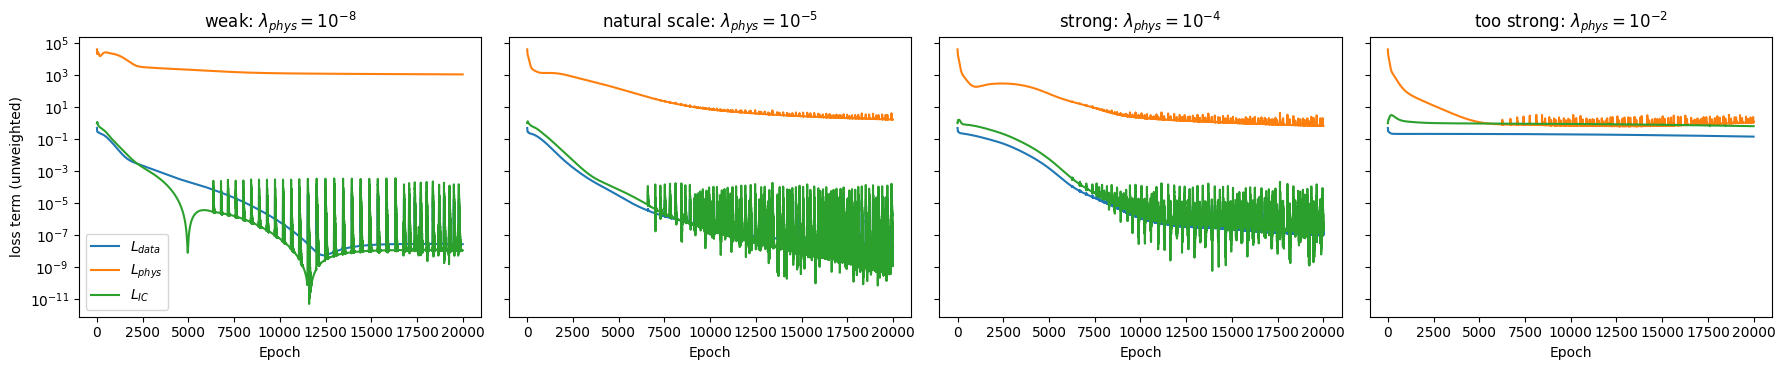

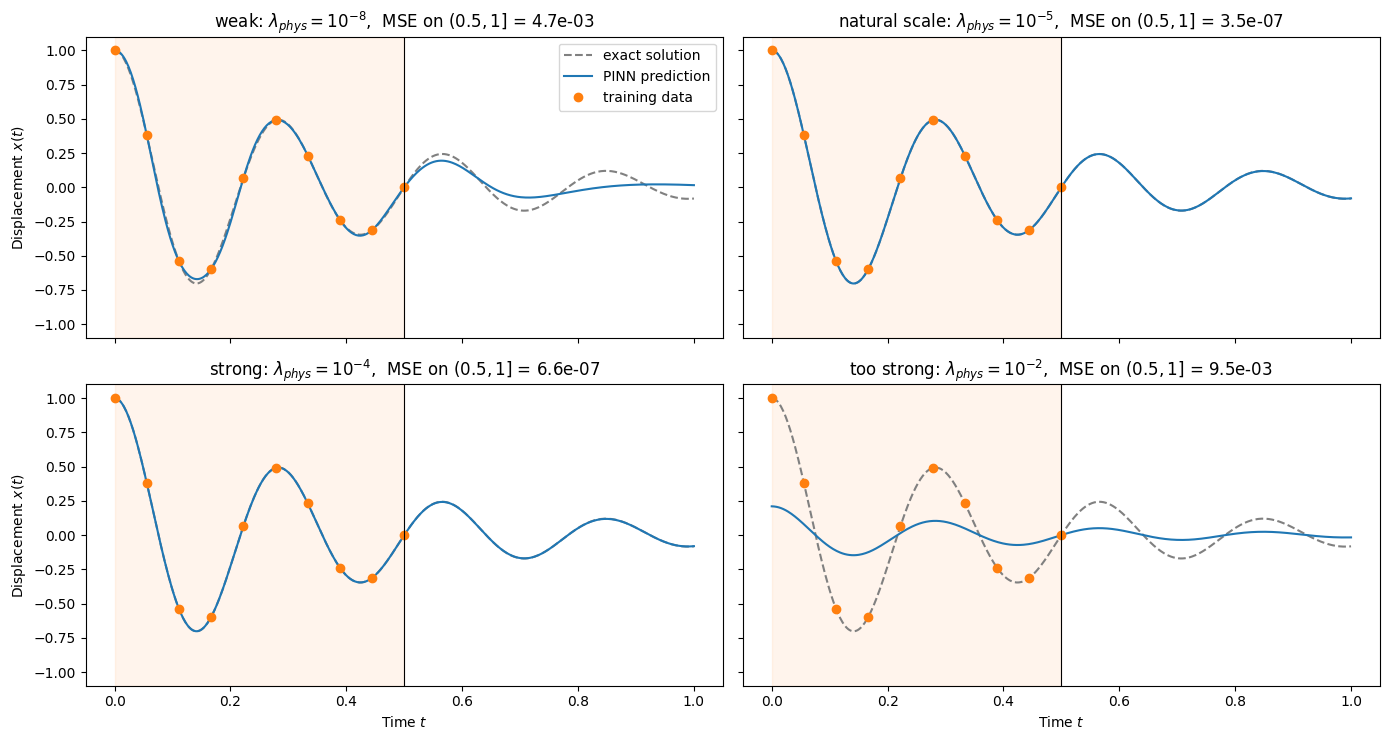

In [19]:
# loss components for different values of lambda_phys comparison

shown = [(1e-8, 'weak'), (1e-5, 'natural scale'), (1e-4, 'strong'), (1e-2, 'too strong')]

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for ax, (lam, label) in zip(axes, shown):
    hist = runs[lam][1]
    ax.semilogy(hist['L_data'], label='$L_{data}$')
    ax.semilogy(hist['L_phys'], label='$L_{phys}$')
    ax.semilogy(hist['L_ic'], label='$L_{IC}$')
    ax.set_title(f'{label}: $\\lambda_{{phys}} = 10^{{{int(np.log10(lam))}}}$')
    ax.set_xlabel('Epoch')
axes[0].set_ylabel('loss term (unweighted)')
axes[0].legend()
plt.tight_layout()
plt.show()


# compare the PINN predictions for different physics loss weights
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True, sharey=True)
for ax, (lam, label) in zip(axes.ravel(), shown):
    x_pred, mse_in, mse_out = evaluate(runs[lam][0])
    ax.plot(t_test, x_exact, color='grey', ls='--', label='exact solution')
    ax.plot(t_test, x_pred, color='tab:blue', label='PINN prediction')
    ax.plot(t_data, x_data, 'o', color='tab:orange', label='training data')
    ax.axvspan(0, 0.5, color='tab:orange', alpha=0.08)
    ax.axvline(0.5, color='k', lw=0.8)
    ax.set_ylim(-1.1, 1.1)
    ax.set_title(f'{label}: $\\lambda_{{phys}} = 10^{{{int(np.log10(lam))}}}$,  MSE on $(0.5, 1]$ = {mse_out:.1e}')
for ax in axes[1]:
    ax.set_xlabel('Time $t$')
for ax in axes[:, 0]:
    ax.set_ylabel('Displacement $x(t)$')
axes[0, 0].legend(loc='upper right')
plt.tight_layout()
plt.show()

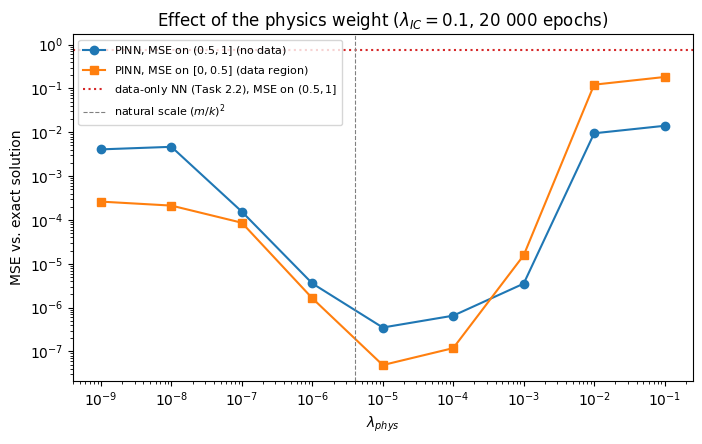

In [20]:
# prediction errors for each value of lambda

mse_in_sweep = [evaluate(runs[lam][0])[1] for lam in lambda_values]
mse_out_sweep = [evaluate(runs[lam][0])[2] for lam in lambda_values]


# plotting the physics loss weight and accuracy 
plt.figure(figsize=(8, 4.5))
plt.loglog(lambda_values, mse_out_sweep, 'o-', label='PINN, MSE on $(0.5, 1]$ (no data)')
plt.loglog(lambda_values, mse_in_sweep, 's-', label='PINN, MSE on $[0, 0.5]$ (data region)')
plt.axhline(mse_out_data_only, color='tab:red', ls=':', label='data-only NN (Task 2.2), MSE on $(0.5, 1]$')
plt.axvline((m / k)**2, color='grey', ls='--', lw=0.8, label='natural scale $(m/k)^2$')
plt.xlabel('$\\lambda_{phys}$')
plt.ylabel('MSE vs. exact solution')
plt.title('Effect of the physics weight ($\\lambda_{IC} = 0.1$, 20 000 epochs)')
plt.legend(fontsize=8)
plt.show()

max |W_1| at initialisation: Glorot 0.67  vs  scaled 20.6  (omega = 22.2)
Glorot init after 20000 epochs: L_data 1.42e-03 | L_phys 4.15e+02 | L_IC 6.93e-06 | MSE [0,0.5] 1.03e-03 | MSE (0.5,1] 1.66e-02
max |W_1| after training: 9.65;  max |x_pred| on (0.5, 1]: 0.096


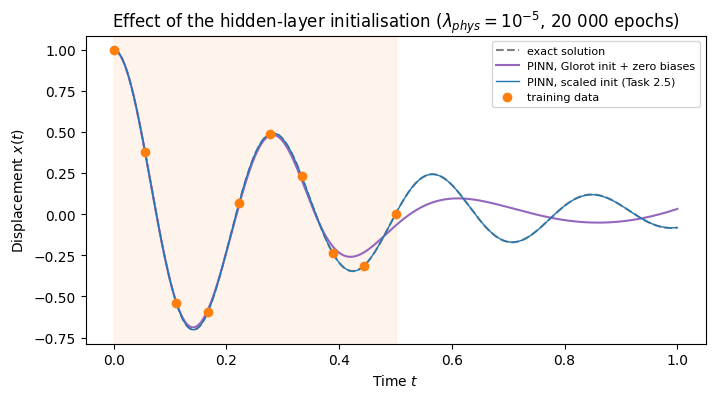

In [21]:
# initialize the network using the Glorot weights and zero biases in the hidden layer

torch.manual_seed(0)
net_glorot = Net(num_hidden)
with torch.no_grad():
    init.xavier_normal_(net_glorot.W_1)
    init.constant_(net_glorot.b_1, 0)

# initial weight magnitudes comparision

print(f"max |W_1| at initialisation: Glorot {net_glorot.W_1.abs().max():.2f}  vs  scaled {Net(num_hidden).W_1.abs().max():.1f}  (omega = {w:.1f})")


# network training and evaluation of the performance
net_glorot, history_glorot = train_pinn_manual(lambda_phys, lambda_ic, net=net_glorot)
x_glorot, mse_in_glorot, mse_out_glorot = evaluate(net_glorot)
print(f"Glorot init after {num_epochs} epochs: L_data {history_glorot['L_data'][-1]:.2e} | L_phys {history_glorot['L_phys'][-1]:.2e} | "
      f"L_IC {history_glorot['L_ic'][-1]:.2e} | MSE [0,0.5] {mse_in_glorot:.2e} | MSE (0.5,1] {mse_out_glorot:.2e}")
print(f"max |W_1| after training: {net_glorot.W_1.abs().max():.2f};  max |x_pred| on (0.5, 1]: {np.abs(x_glorot[outside]).max():.3f}")


# predictions from the two initialisation methods
plt.figure(figsize=(8, 4))
plt.plot(t_test, x_exact, color='grey', ls='--', label='exact solution')
plt.plot(t_test, x_glorot, color='tab:purple', label='PINN, Glorot init + zero biases')
plt.plot(t_test, evaluate(net_pinn)[0], color='tab:blue', lw=1, label='PINN, scaled init (Task 2.5)')
plt.plot(t_data, x_data, 'o', color='tab:orange', label='training data')
plt.axvspan(0, 0.5, color='tab:orange', alpha=0.08)
plt.xlabel('Time $t$')
plt.ylabel('Displacement $x(t)$')
plt.title('Effect of the hidden-layer initialisation ($\\lambda_{phys} = 10^{-5}$, 20 000 epochs)')
plt.legend(fontsize=8)
plt.show()

In [22]:
def loss_autograd(net, lambda_phys, lambda_ic):

    # data loss based on the training points

    L_data = torch.mean((net(t_train) - x_train)**2)

    # first and second time derivatives
    t_c = t_phys.clone().requires_grad_(True)
    x_c = net(t_c)
    dx_c = torch.autograd.grad(x_c, t_c, torch.ones_like(x_c), create_graph=True)[0]
    d2x_c = torch.autograd.grad(dx_c, t_c, torch.ones_like(dx_c), create_graph=True)[0]
    r = d2x_c + mu / m * dx_c + k / m * x_c
    L_phys = torch.mean(r**2)

    # initial conditions at t = 0

    t_ic = t_0.clone().requires_grad_(True)
    x_0 = net(t_ic)
    dx_0 = torch.autograd.grad(x_0, t_ic, torch.ones_like(x_0), create_graph=True)[0]
    L_ic = torch.sum((x_0 - 1)**2 + dx_0**2)

    # combine three loss terms

    L = L_data + lambda_phys * L_phys + lambda_ic * L_ic
    return L, (L_data, L_phys, L_ic)


def train_pinn_autograd(lambda_phys, lambda_ic, num_epochs=num_epochs, lr=lr, seed=0):

# network and optimizer initialization

    torch.manual_seed(seed)
    net = Net(num_hidden)
    optimizer = optim.Adam(net.parameters(), lr=lr)
    history = {"L": [], "L_data": [], "L_phys": [], "L_ic": []}

# train the network using automatically calculated gradients

    for epoch in range(num_epochs):
        L, (L_data, L_phys, L_ic) = loss_autograd(net, lambda_phys, lambda_ic)
        grads = torch.autograd.grad(L, list(net.parameters()))
        for p, g in zip(net.parameters(), grads):
            p.grad = g
        optimizer.step()
        # store loss values for each epoch

        for key, value in zip(history, (L, L_data, L_phys, L_ic)):
            history[key].append(value.item())
    return net, history

In [23]:
torch.manual_seed(0)
net_init = Net(num_hidden)

L_auto, parts_auto = loss_autograd(net_init, lambda_phys, lambda_ic)
grads_auto = torch.autograd.grad(L_auto, list(net_init.parameters()))
L_man, parts_man, grads_man = loss_and_grads(*[p.detach() for p in net_init.parameters()], lambda_phys, lambda_ic)

print(f"loss  : hand-derived {L_man:.15e} | autograd {L_auto:.15e} | rel. difference {abs(L_man - L_auto) / L_auto:.1e}")
print(f"\n{'parameter':10s} {'||grad||':>12s} {'||hand - autograd|| / ||autograd||':>36s}")
for name, g_m, g_a in zip(param_names, grads_man, grads_auto):
    print(f"{name:10s} {g_a.norm():12.4e} {((g_m - g_a).norm() / g_a.norm()):36.2e}")
g_m_all = torch.cat([g.view(-1) for g in grads_man])
g_a_all = torch.cat([g.view(-1) for g in grads_auto])
print(f"{'all 97':10s} {g_a_all.norm():12.4e} {((g_m_all - g_a_all).norm() / g_a_all.norm()):36.2e}")

loss  : hand-derived 9.809085893881965e-01 | autograd 9.809085893881965e-01 | rel. difference 0.0e+00

parameter      ||grad||   ||hand - autograd|| / ||autograd||
W_1          4.1609e-01                             1.03e-16
b_1          9.3663e-01                             1.72e-16
W_2          8.0756e+00                             2.03e-16
b_2          1.9426e+00                             0.00e+00
all 97       8.3690e+00                             1.96e-16


In [24]:
start = time.time()
net_auto, history_auto = train_pinn_autograd(lambda_phys, lambda_ic)
time_auto = time.time() - start
print(f"Training time: hand-derived {time_manual:.1f} s | autograd {time_auto:.1f} s  ({time_auto / time_manual:.1f}x)")

x_man, mse_in_man, mse_out_man = evaluate(net_pinn)
x_auto, mse_in_auto, mse_out_auto = evaluate(net_auto)
print(f"\n{'':14s} {'final L':>10s} {'L_data':>10s} {'L_phys':>10s} {'L_IC':>10s} {'MSE [0,0.5]':>12s} {'MSE (0.5,1]':>12s}")
for name, hist, mi, mo in [("hand-derived", history_pinn, mse_in_man, mse_out_man), ("autograd", history_auto, mse_in_auto, mse_out_auto)]:
    print(f"{name:14s} {hist['L'][-1]:10.3e} {hist['L_data'][-1]:10.3e} {hist['L_phys'][-1]:10.3e} {hist['L_ic'][-1]:10.3e} {mi:12.2e} {mo:12.2e}")
print(f"\nmax |x_hand(t) - x_autograd(t)| on [0, 1]: {np.abs(x_man - x_auto).max():.1e}")

Training time: hand-derived 13.0 s | autograd 12.6 s  (1.0x)

                  final L     L_data     L_phys       L_IC  MSE [0,0.5]  MSE (0.5,1]
hand-derived    1.643e-05  1.748e-08  1.641e+00  2.135e-08     4.89e-08     3.51e-07
autograd        1.641e-05  2.541e-08  1.638e+00  1.424e-08     5.65e-08     3.57e-07

max |x_hand(t) - x_autograd(t)| on [0, 1]: 1.2e-04


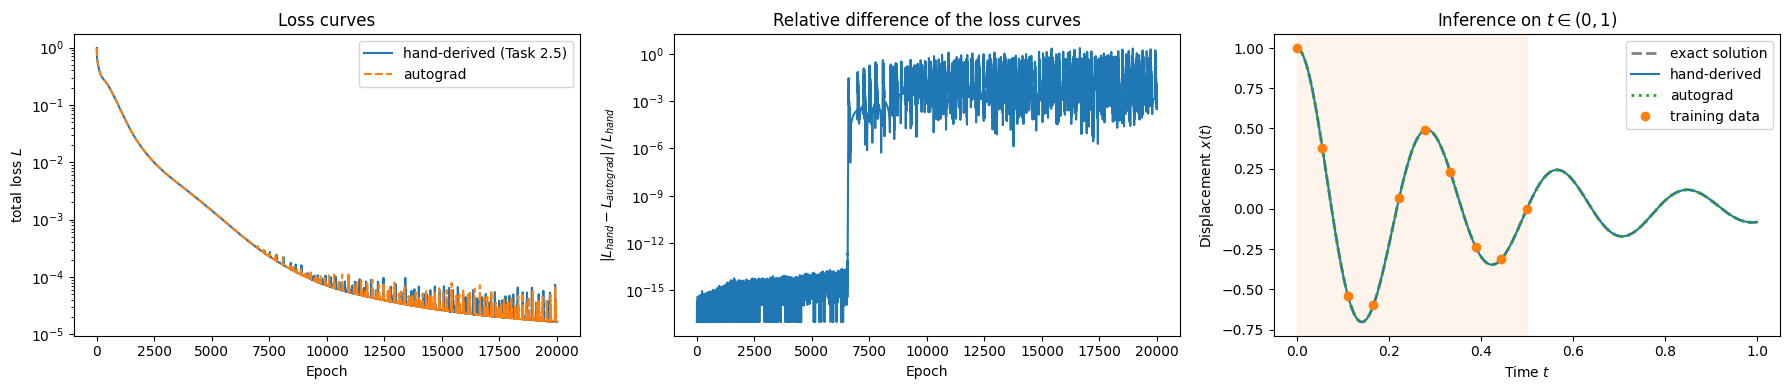

first epoch where the loss curves differ by more than 1e-6 (relative): 6579


In [25]:
L_man_curve, L_auto_curve = np.array(history_pinn['L']), np.array(history_auto['L'])
rel_diff = np.abs(L_man_curve - L_auto_curve) / L_man_curve

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4))

ax1.semilogy(L_man_curve, label='hand-derived (Task 2.5)')
ax1.semilogy(L_auto_curve, '--', label='autograd')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('total loss $L$')
ax1.set_title('Loss curves')
ax1.legend()

ax2.semilogy(np.maximum(rel_diff, 1e-17))
ax2.set_xlabel('Epoch')
ax2.set_ylabel('$|L_{hand} - L_{autograd}| \\, / \\, L_{hand}$')
ax2.set_title('Relative difference of the loss curves')

ax3.plot(t_test, x_exact, color='grey', ls='--', lw=2, label='exact solution')
ax3.plot(t_test, x_man, color='tab:blue', label='hand-derived')
ax3.plot(t_test, x_auto, color='tab:green', ls=':', lw=2, label='autograd')
ax3.plot(t_data, x_data, 'o', color='tab:orange', label='training data')
ax3.axvspan(0, 0.5, color='tab:orange', alpha=0.08)
ax3.set_xlabel('Time $t$')
ax3.set_ylabel('Displacement $x(t)$')
ax3.set_title('Inference on $t \\in (0, 1)$')
ax3.legend()
plt.tight_layout()
plt.show()

first = np.argmax(rel_diff > 1e-6) if (rel_diff > 1e-6).any() else None
print("first epoch where the loss curves differ by more than 1e-6 (relative):", first)

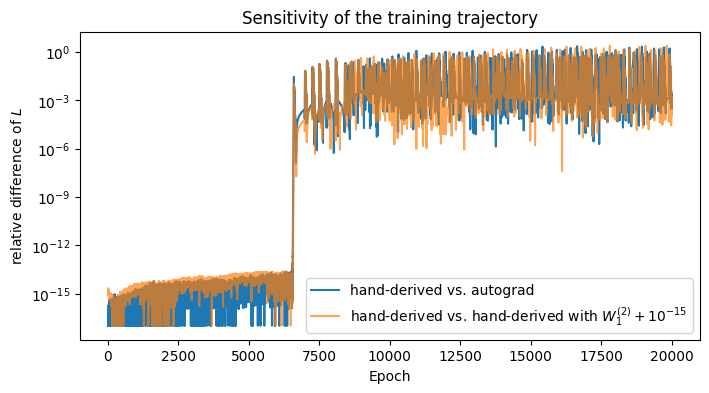

first epoch with relative difference > 1e-6: hand vs autograd 6579, hand vs perturbed hand 6583
perturbed run: MSE on (0.5, 1] = 3.50e-07
epochs for the relative difference to grow from 1e-12 to 1e-3: hand vs autograd 28, hand vs perturbed hand 28


In [26]:

torch.manual_seed(0)
net_pert = Net(num_hidden)
with torch.no_grad():
    net_pert.W_2.view(-1)[0] += 1e-15
net_pert, history_pert = train_pinn_manual(lambda_phys, lambda_ic, net=net_pert)
rel_diff_pert = np.abs(L_man_curve - np.array(history_pert['L'])) / L_man_curve

plt.figure(figsize=(8, 4))
plt.semilogy(np.maximum(rel_diff, 1e-17), label='hand-derived vs. autograd')
plt.semilogy(np.maximum(rel_diff_pert, 1e-17), alpha=0.7, label='hand-derived vs. hand-derived with $W^{(2)}_1 + 10^{-15}$')
plt.xlabel('Epoch')
plt.ylabel('relative difference of $L$')
plt.title('Sensitivity of the training trajectory')
plt.legend()
plt.show()

first_pert = np.argmax(rel_diff_pert > 1e-6)
print(f"first epoch with relative difference > 1e-6: hand vs autograd {first}, hand vs perturbed hand {first_pert}")
print(f"perturbed run: MSE on (0.5, 1] = {evaluate(net_pert)[2]:.2e}")
grow = lambda rd: int(np.argmax(rd > 1e-3) - np.argmax(rd > 1e-12))
print(f"epochs for the relative difference to grow from 1e-12 to 1e-3: hand vs autograd {grow(rel_diff)}, hand vs perturbed hand {grow(rel_diff_pert)}")


In [27]:
class HardIC(nn.Module):

    def __init__(self, net):
        super(HardIC, self).__init__()
        self.net = net

    def forward(self, t):
        return 1 + t**2 * self.net(t)


def hard_derivatives(t, W_1, b_1, W_2, b_2):
    _, _, x, dx, d2x = network_derivatives(t, W_1, b_1, W_2, b_2)
    xh = 1 + t**2 * x
    dxh = 2 * t * x + t**2 * dx
    d2xh = 2 * x + 4 * t * dx + t**2 * d2x
    return xh, dxh, d2xh


def grads_hard(t, a_h, b_h, c_h, *params):
    a = t**2 * a_h + 2 * t * b_h + 2 * c_h
    b = t**2 * b_h + 4 * t * c_h
    c = t**2 * c_h
    return param_grads(t, a, b, c, *params)


def loss_and_grads_hard(W_1, b_1, W_2, b_2, lambda_phys, lambda_ic=0.0):
    params = (W_1, b_1, W_2, b_2)

    x_d, _, _ = hard_derivatives(t_train, *params)
    e = x_d - x_train
    L_data = torch.mean(e**2)

    x_c, dx_c, d2x_c = hard_derivatives(t_phys, *params)
    r = d2x_c + mu / m * dx_c + k / m * x_c
    L_phys = torch.mean(r**2)

    x_0, dx_0, _ = hard_derivatives(t_0, *params)
    ic_violation = torch.sum((x_0 - 1)**2 + dx_0**2)

    L = L_data + lambda_phys * L_phys

    zeros_d = torch.zeros_like(e)
    dL_dr = 2 * lambda_phys * r / len(t_phys)
    g_data = grads_hard(t_train, 2 * e / len(t_train), zeros_d, zeros_d, *params)
    g_phys = grads_hard(t_phys, k / m * dL_dr, mu / m * dL_dr, dL_dr, *params)
    grads = [gd + gp for gd, gp in zip(g_data, g_phys)]

    return L, (L_data, L_phys, ic_violation), grads

In [28]:
torch.manual_seed(0)
net_init = Net(num_hidden)
params = [p.detach() for p in net_init.parameters()]
L_h, parts_h, grads_h = loss_and_grads_hard(*params, lambda_phys)

hard_init = HardIC(net_init)
t_c = t_phys.clone().requires_grad_(True)
x_c = hard_init(t_c)
dx_c = torch.autograd.grad(x_c, t_c, torch.ones_like(x_c), create_graph=True)[0]
d2x_c = torch.autograd.grad(dx_c, t_c, torch.ones_like(dx_c), create_graph=True)[0]
r = d2x_c + mu / m * dx_c + k / m * x_c
L_h_auto = torch.mean((hard_init(t_train) - x_train)**2) + lambda_phys * torch.mean(r**2)
grads_h_auto = torch.autograd.grad(L_h_auto, list(net_init.parameters()))

print(f"loss: hand-derived {L_h:.12e} | autograd {L_h_auto:.12e}")
for name, g_m, g_a in zip(param_names, grads_h, grads_h_auto):
    print(f"dL/d{name}: ||hand - autograd|| / ||autograd|| = {((g_m - g_a).norm() / g_a.norm()):.1e}")

x0, dx0, _ = hard_derivatives(t_0, *params)
print(f"\nuntrained network: x(0) - 1 = {(x0 - 1).item():.1e},  dx/dt(0) = {dx0.item():.1e}")
print(f"at initialisation: L_data = {parts_h[0]:.2e}, L_phys = {parts_h[1]:.2e}  (soft version: L_phys = {parts_man[1]:.2e})")

loss: hand-derived 4.231017127399e+00 | autograd 4.231017127399e+00
dL/dW_1: ||hand - autograd|| / ||autograd|| = 7.0e-17
dL/db_1: ||hand - autograd|| / ||autograd|| = 7.5e-17
dL/dW_2: ||hand - autograd|| / ||autograd|| = 1.2e-16
dL/db_2: ||hand - autograd|| / ||autograd|| = 0.0e+00

untrained network: x(0) - 1 = 0.0e+00,  dx/dt(0) = 0.0e+00
at initialisation: L_data = 1.22e+00, L_phys = 3.01e+05  (soft version: L_phys = 3.99e+04)


In [29]:
start = time.time()
net_hard, history_hard = train_pinn_manual(lambda_phys, 0.0, loss_fn=loss_and_grads_hard)
print(f"Training time: {time.time() - start:.1f} s")


def ic_errors(net, hard):
    params = [p.detach() for p in net.parameters()]
    if hard:
        x0, dx0, _ = hard_derivatives(t_0, *params)
    else:
        _, _, x0, dx0, _ = network_derivatives(t_0, *params)
    return abs(x0.item() - 1), abs(dx0.item())


x_soft, mse_in_soft, mse_out_soft = evaluate(net_pinn)
x_hard, mse_in_hard, mse_out_hard = evaluate(HardIC(net_hard))
print(f"\n{'':6s} {'|x(0) - 1|':>11s} {'|dx/dt(0)|':>11s} {'L_data':>10s} {'L_phys':>10s} {'MSE [0,0.5]':>12s} {'MSE (0.5,1]':>12s}")
for name, net_, hard, hist, mi, mo in [("soft", net_pinn, False, history_pinn, mse_in_soft, mse_out_soft),
                                       ("hard", net_hard, True, history_hard, mse_in_hard, mse_out_hard)]:
    e0, de0 = ic_errors(net_, hard)
    print(f"{name:6s} {e0:11.1e} {de0:11.1e} {hist['L_data'][-1]:10.2e} {hist['L_phys'][-1]:10.2e} {mi:12.2e} {mo:12.2e}")

Training time: 12.6 s

        |x(0) - 1|  |dx/dt(0)|     L_data     L_phys  MSE [0,0.5]  MSE (0.5,1]
soft       1.4e-06     3.5e-05   1.75e-08   1.64e+00     4.89e-08     3.51e-07
hard       0.0e+00     0.0e+00   1.42e-03   4.29e+02     1.49e-03     6.94e-05


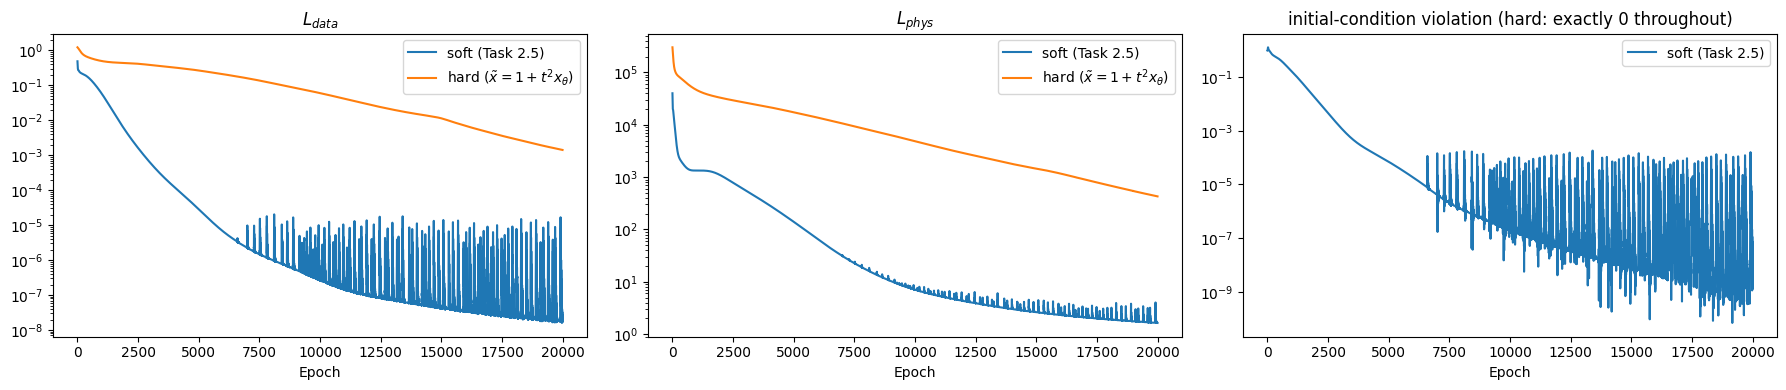

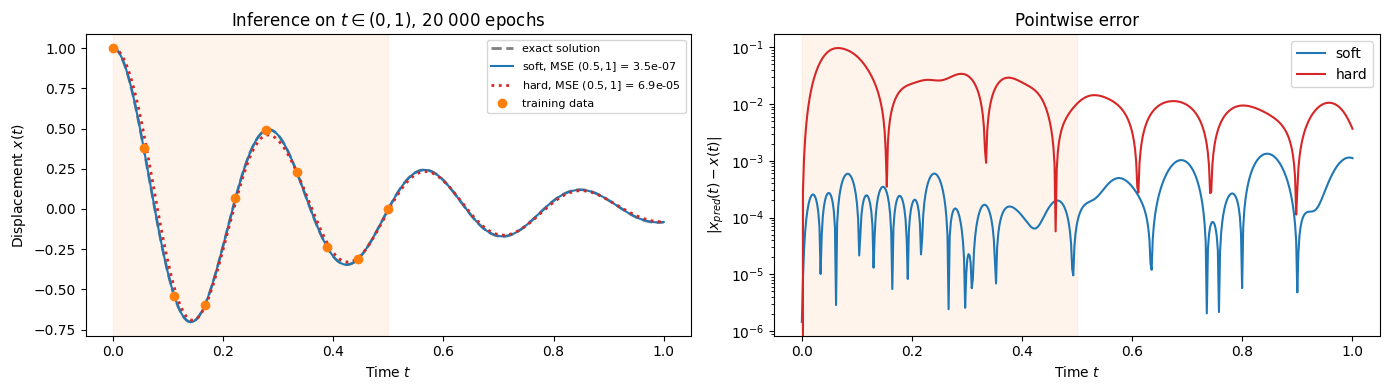

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, key, title in zip(axes, ['L_data', 'L_phys', 'L_ic'], ['$L_{data}$', '$L_{phys}$', 'initial-condition violation']):
    ax.semilogy(history_pinn[key], label='soft (Task 2.5)')
    if key != 'L_ic':
        ax.semilogy(history_hard[key], label='hard ($\\tilde x = 1 + t^2 x_\\theta$)')
    ax.set_xlabel('Epoch')
    ax.set_title(title)
    ax.legend()
axes[2].set_title('initial-condition violation (hard: exactly 0 throughout)')
plt.tight_layout()
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(t_test, x_exact, color='grey', ls='--', lw=2, label='exact solution')
ax1.plot(t_test, x_soft, color='tab:blue', label=f'soft, MSE $(0.5,1]$ = {mse_out_soft:.1e}')
ax1.plot(t_test, x_hard, color='tab:red', ls=':', lw=2, label=f'hard, MSE $(0.5,1]$ = {mse_out_hard:.1e}')
ax1.plot(t_data, x_data, 'o', color='tab:orange', label='training data')
ax1.axvspan(0, 0.5, color='tab:orange', alpha=0.08)
ax1.set_xlabel('Time $t$')
ax1.set_ylabel('Displacement $x(t)$')
ax1.set_title('Inference on $t \\in (0, 1)$, 20 000 epochs')
ax1.legend(fontsize=8)

ax2.semilogy(t_test, np.abs(x_soft - x_exact), color='tab:blue', label='soft')
ax2.semilogy(t_test, np.abs(x_hard - x_exact), color='tab:red', label='hard')
ax2.axvspan(0, 0.5, color='tab:orange', alpha=0.08)
ax2.set_xlabel('Time $t$')
ax2.set_ylabel('$|x_{pred}(t) - x(t)|$')
ax2.set_title('Pointwise error')
ax2.legend()
plt.tight_layout()
plt.show()

In [31]:
results = {"soft": {0: (mse_out_soft, *ic_errors(net_pinn, False))},
           "hard": {0: (mse_out_hard, *ic_errors(net_hard, True))}}
for seed in [1, 2]:
    net_s, _ = train_pinn_manual(lambda_phys, lambda_ic, seed=seed)
    results["soft"][seed] = (evaluate(net_s)[2], *ic_errors(net_s, False))
    net_h, _ = train_pinn_manual(lambda_phys, 0.0, seed=seed, loss_fn=loss_and_grads_hard)
    results["hard"][seed] = (evaluate(HardIC(net_h))[2], *ic_errors(net_h, True))

print(f"{'':6s} {'seed':>4s} {'MSE (0.5,1]':>12s} {'|x(0) - 1|':>11s} {'|dx/dt(0)|':>11s}")
for name in ["soft", "hard"]:
    for seed, (mo, e0, de0) in results[name].items():
        print(f"{name:6s} {seed:4d} {mo:12.2e} {e0:11.1e} {de0:11.1e}")

net_hard_long, history_hard_long = train_pinn_manual(lambda_phys, 0.0, num_epochs=3 * num_epochs, loss_fn=loss_and_grads_hard)
_, _, mse_out_hard_long = evaluate(HardIC(net_hard_long))
print(f"\nhard, seed 0, 60 000 epochs: L_data = {history_hard_long['L_data'][-1]:.1e}, MSE (0.5,1] = {mse_out_hard_long:.2e}")

       seed  MSE (0.5,1]  |x(0) - 1|  |dx/dt(0)|
soft      0     3.51e-07     1.4e-06     3.5e-05
soft      1     1.23e-05     1.2e-03     3.4e-05
soft      2     1.18e-06     7.5e-04     3.0e-04
hard      0     6.94e-05     0.0e+00     0.0e+00
hard      1     1.81e-03     0.0e+00     0.0e+00
hard      2     2.98e-03     0.0e+00     0.0e+00

hard, seed 0, 60 000 epochs: L_data = 8.6e-06, MSE (0.5,1] = 3.42e-06


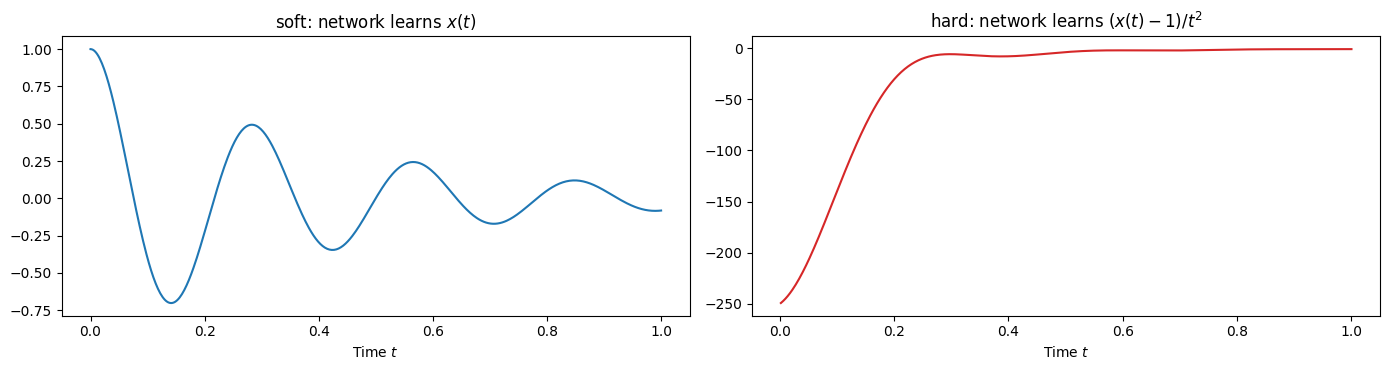

range of x(t): [-0.70, 1.00]   range of (x - 1)/t^2: [-249.1, -1.08]


In [32]:
g_target = (x_exact[1:] - 1) / t_test[1:]**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 3.8))
ax1.plot(t_test, x_exact, color='tab:blue')
ax1.set_title('soft: network learns $x(t)$')
ax2.plot(t_test[1:], g_target, color='tab:red')
ax2.set_title('hard: network learns $(x(t) - 1)/t^2$')
for ax in (ax1, ax2):
    ax.set_xlabel('Time $t$')
plt.tight_layout()
plt.show()
print(f"range of x(t): [{x_exact.min():.2f}, {x_exact.max():.2f}]   range of (x - 1)/t^2: [{g_target.min():.1f}, {g_target.max():.2f}]")

In [33]:
torch.manual_seed(0)
net_seed0 = Net(num_hidden)
print(f"{'network':26s} {'sum |W_2|':>10s} {'net output at t=0':>18s}")
with torch.no_grad():
    for name, net_ in [("initialisation (seed 0)", net_seed0), ("soft, 20 000 epochs", net_pinn),
                       ("hard, 20 000 epochs", net_hard), ("hard, 60 000 epochs", net_hard_long)]:
        print(f"{name:26s} {net_.W_2.abs().sum():10.1f} {net_(t_0).item():18.1f}")
print(f"{'target for hard: (x-1)/t^2 -> -k/2m':26s} {'':10s} {-k / (2 * m):18.1f}")

network                     sum |W_2|  net output at t=0
initialisation (seed 0)           5.7                0.1
soft, 20 000 epochs              10.9                1.0
hard, 20 000 epochs             196.1             -179.5
hard, 60 000 epochs             245.4             -228.7
target for hard: (x-1)/t^2 -> -k/2m                        -250.0
